# LIF 神经元仿真与可视化

模拟单个神经元对输入电流的响应，逐项观察输入、膜电位、脉冲和发放率。

[查看作业题目](homework-2.pdf)


## 1. LIF 神经元模型

LIF 的本质是：**输入电流改变膜电位，泄漏使膜电位趋向静息值**。发放和重置前，膜电位满足：

$$\tau_m\frac{dV(t)}{dt}=-(V(t)-V_{\mathrm{rest}})+RI(t)$$

其中：

- $V$ 和 $V_{\mathrm{rest}}$：当前膜电位和静息电位；
- $\frac{dV}{dt}$：膜电位随时间变化的速度；
- $-(V-V_{\mathrm{rest}})$：泄漏，使膜电位趋向静息值；
- $RI(t)$：输入电流的作用；
- $\tau_m$：膜时间常数，影响电位变化的快慢。

令 $k$ 为时间步编号，$t_k=k\Delta t$。使用前向 Euler 方法，将连续变化近似为离散更新：

$$V_{k+1}=V_k+\frac{\Delta t}{\tau_m}\left[-(V_k-V_{\mathrm{rest}})+RI_k\right]$$

达到阈值后的脉冲发放、重置和不应期是额外规则。下面的 `LIFNeuron` 在内部适配 `snn.Leaky`，对外使用题目中的物理参数。

In [1]:
import sys
from pathlib import Path

import numpy as np

# 支持从项目根目录或 lif 目录启动。
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "lif" else Path.cwd()))

## 2. 模拟一个神经元

`LIFNeuron` 接受电流（nA），返回膜电位（mV）和脉冲 Tensor。达到阈值时发放并立即重置到静息电位，随后 2 ms 不应期内保持静息电位、不发放。使用 snnTorch 代理梯度让脉冲在反向传播时可近似求导；不应期仍是离散状态。

每次新序列调用 `reset_state()` 回到静息电位；反向传播跨时间步时应在序列结束后重置状态。

In [2]:
# 电位 mV、时间 ms、电阻 MΩ、电流 nA；dt 和 tau_m 对应公式中的 Δt 和 τₘ
V_rest, V_th = -65.0, -50.0
dt, tau_m, R = 0.1, 20.0, 10.0
refractory_ms, duration_ms = 2.0, 2000.0

In [3]:
from lif.model import LIFNeuron, firing_rate, simulate_current

In [4]:
def simulate(I, duration_ms, dt):
    neuron = LIFNeuron(dt, tau_m, R, V_rest, V_th, refractory_ms)
    return simulate_current(I, duration_ms, dt, neuron)

## 3. 输入电流与可视化

先使用恒定电流逐项观察输入、膜电位、脉冲序列和发放率，再用四联图对照恒定和正弦输入。默认仿真 2 秒，图中展示前 200 ms。

正弦输入为 $I(t)=I_0+A\sin(2\pi ft+\phi)$。$I_0$ 和 $A$ 的单位是 nA，$f$ 的单位是 Hz，$\phi$ 的单位是弧度；计算时将毫秒转换为秒。图形由 `plot_lif.py` 中的函数绘制。


In [5]:
from lif.plot_lif import plot_individual, plot_summary

input_time_ms = np.arange(round(duration_ms / dt)) * dt
time_ms = input_time_ms + dt
I_0, A, f, phi = 2.0, 0.8, 5.0, 0.0
currents = {
    "Constant input (2 nA)": np.full_like(input_time_ms, 2.0),
    "Sinusoidal input": I_0 + A * np.sin(2 * np.pi * f * input_time_ms / 1000 + phi),
}
examples = {}
for name, current in currents.items():
    voltage, spikes = simulate(current, duration_ms, dt)
    examples[name] = {
        "input_time_ms": input_time_ms,
        "time_ms": time_ms,
        "current": current,
        "voltage": voltage,
        "spikes": spikes,
    }
constant_example = examples["Constant input (2 nA)"]

### 3.1 输入电流

每个时间步使用该步开始时的电流值，计算步末的膜电位。这里展示 2 nA 的恒定电流。正弦电流采用题目推荐参数：基础电流 2 nA、振幅 0.8 nA、频率 5 Hz，相位取 0。


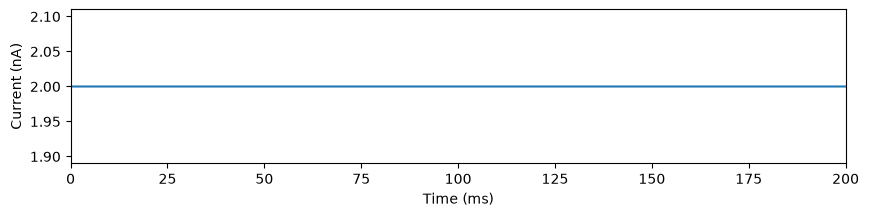

In [6]:
plot_individual(constant_example, "current", V_rest, V_th)

### 3.2 膜电位

输入电流与泄漏共同影响膜电位；达到阈值后发放并重置到静息电位。记录的是每一步结束后的电位，因此发放时看到的是静息电位。


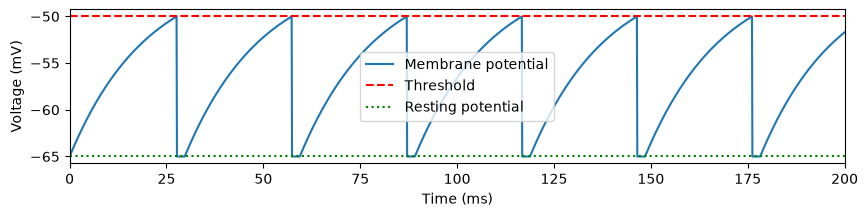

In [7]:
plot_individual(constant_example, "voltage", V_rest, V_th)

### 3.3 脉冲序列

每条竖线表示一次实际检测到的脉冲。


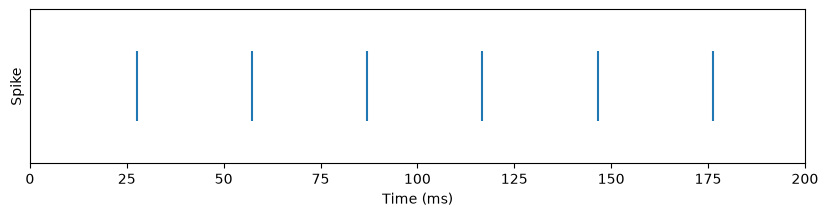

脉冲总数：67


In [8]:
plot_individual(constant_example, "spikes", V_rest, V_th)
print(f"脉冲总数：{int(constant_example['spikes'].sum())}")

### 3.4 发放率

以最近约 100 ms 内的实际脉冲数除以窗口时长，得到发放率（Hz）。窗口取最接近 100 ms 的整数个时间步；开始阶段按已有时间计算。


In [9]:
# 发放率函数与桌面程序共用，见 model.py。

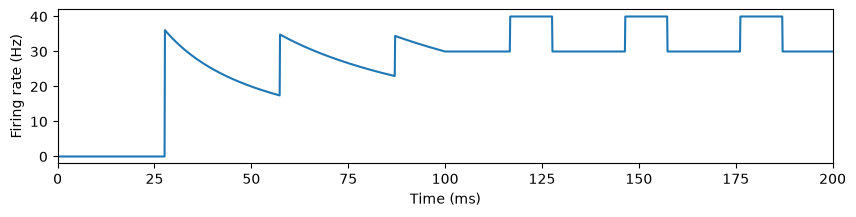

全程平均发放率：33.5 Hz


In [10]:
for data in examples.values():
    data["rate"] = firing_rate(data["spikes"], dt)
plot_individual(constant_example, "rate", V_rest, V_th)
average_rate = constant_example["spikes"].sum() / (
    len(constant_example["spikes"]) * dt / 1000
)
print(f"全程平均发放率：{average_rate:.1f} Hz")

## 4. 用理论检查实现

默认神经元参数下，恒定输入的临界电流为 $(V_{th}-V_{rest})/R=1.5$ nA。低于临界值时电位达不到阈值；恰好等于临界值时电位渐近接近阈值，在有限时间内也不发放。

分别把恒定电流设为 1、1.5 和 2 nA，重新运行，观察脉冲是否出现。这个临界值结论针对恒定电流；对于周期输入，发放还取决于电流的时间变化。


## 5. 四种信号对照

分别将恒定输入和正弦输入的四种信号放在同一时间轴上，观察输入、膜电位变化、脉冲与发放率之间的关系。


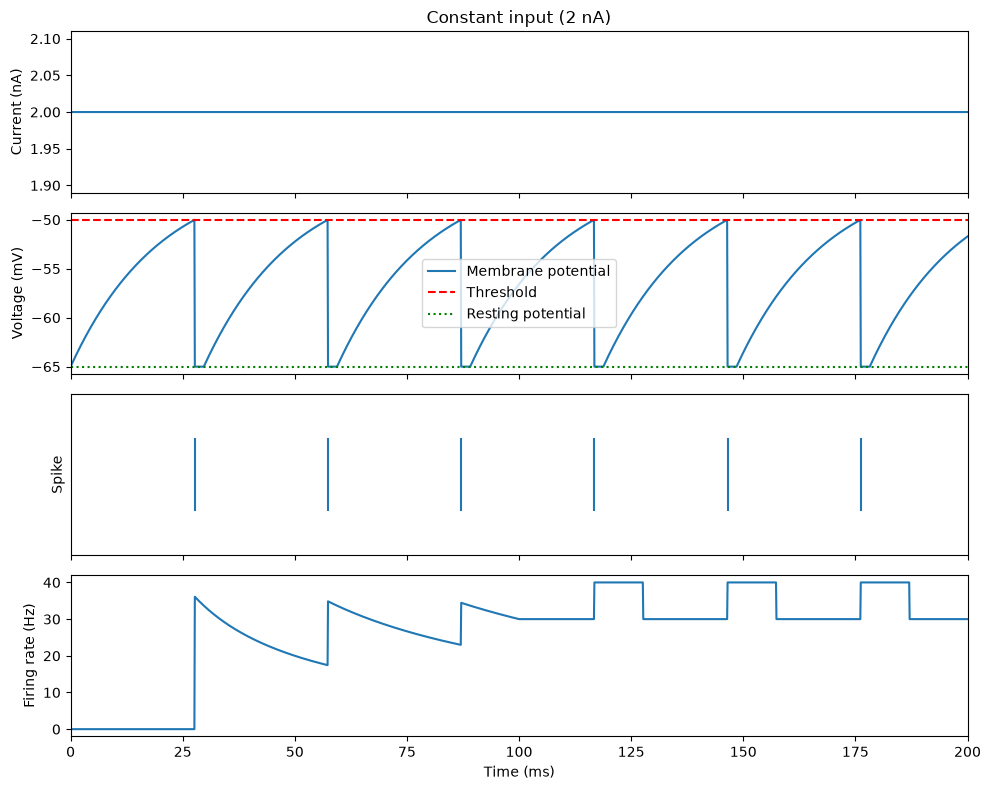

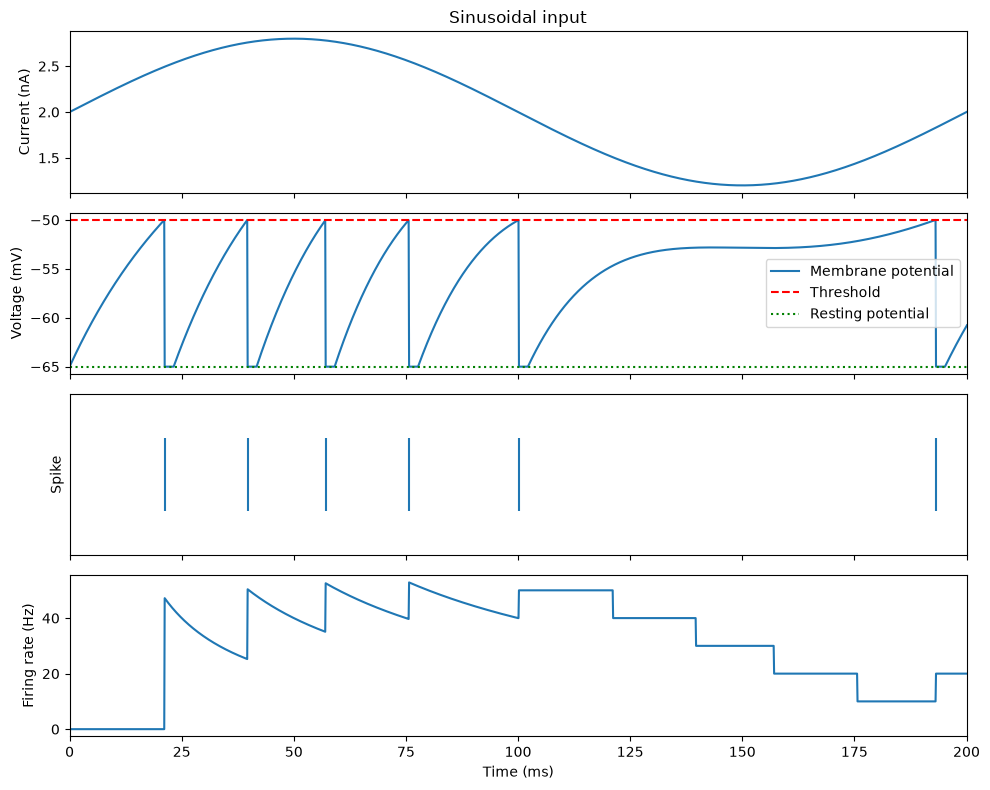

In [11]:
for name, data in examples.items():
    plot_summary(name, data, V_rest, V_th)